In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer 
import seaborn as sns
from IPython.display import display 

In [2]:
DataFile = pd.read_csv('.../covid_19_data.csv')

# Data inspection

In [10]:

pd.reset_option('display.max_rows')
pd.reset_option('display.max_columns')

DataFile

,SNo,ObservationDate,Province/State,Country/Region,Last Update,Confirmed,Deaths,Recovered,Unnamed: 8
0,1,01/22/2020,Anhui,Mainland China,1/22/2020 17:00,1,0,0,NaN
1,2,01/22/2020,Beijing,Mainland China,1/22/2020 17:00,14,0,0,NaN
2,3,01/22/2020,Chongqing,Mainland China,1/22/2020 17:00,6,0,0,NaN
3,4,01/22/2020,Fujian,Mainland China,1/22/2020 17:00,1,0,0,NaN
4,5,01/22/2020,Gansu,Mainland China,1/22/2020 17:00,0,0,0,NaN
...,...,...,...,...,...,...,...,...,...
4242,4243,03/08/2020,Northern Territory,Australia,2020-03-06T04:33:03,0,0,0,NaN
4243,4244,03/08/2020,"Lackland, TX (From Diamond Princess)",US,2020-02-24T23:33:02,0,0,0,NaN
4244,4245,03/08/2020,"Montgomery County, TX",US,2020-03-07T19:53:02,0,0,0,NaN
4245,4246,03/08/2020,"Omaha, NE (From Diamond Princess)",US,2020-02-24T23:33:02,0,0,0,NaN


In [6]:
DataFile.head()

,SNo,ObservationDate,Province/State,Country/Region,Last Update,Confirmed,Deaths,Recovered,Unnamed: 8
0,1,01/22/2020,Anhui,Mainland China,1/22/2020 17:00,1,0,0,NaN
1,2,01/22/2020,Beijing,Mainland China,1/22/2020 17:00,14,0,0,NaN
2,3,01/22/2020,Chongqing,Mainland China,1/22/2020 17:00,6,0,0,NaN
3,4,01/22/2020,Fujian,Mainland China,1/22/2020 17:00,1,0,0,NaN
4,5,01/22/2020,Gansu,Mainland China,1/22/2020 17:00,0,0,0,NaN


In [7]:
DataFile.describe()

,SNo,Confirmed,Deaths,Recovered,Unnamed: 8
count,4247.000000,4247.000000,4247.000000,4247.000000,0.0
mean,2124.000000,586.884624,17.530257,187.914528,NaN
std,1226.147626,5033.596411,190.278672,1976.388824,NaN
min,1.000000,0.000000,0.000000,0.000000,NaN
25%,1062.500000,1.000000,0.000000,0.000000,NaN
50%,2124.000000,9.000000,0.000000,1.000000,NaN
75%,3185.500000,99.500000,1.000000,16.000000,NaN
max,4247.000000,67707.000000,2986.000000,45235.000000,NaN


In [8]:
DataFile.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4247 entries, 0 to 4246
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   SNo              4247 non-null   int64  
 1   ObservationDate  4247 non-null   object 
 2   Province/State   2746 non-null   object 
 3   Country/Region   4247 non-null   object 
 4   Last Update      4247 non-null   object 
 5   Confirmed        4247 non-null   int64  
 6   Deaths           4247 non-null   int64  
 7   Recovered        4247 non-null   int64  
 8   Unnamed: 8       0 non-null      float64
dtypes: float64(1), int64(4), object(4)
memory usage: 298.7+ KB


In [9]:
DataFile.shape

(4247, 9)

In [10]:
DataFile.isna().head()

,SNo,ObservationDate,Province/State,Country/Region,Last Update,Confirmed,Deaths,Recovered,Unnamed: 8
0,False,False,False,False,False,False,False,False,True
1,False,False,False,False,False,False,False,False,True
2,False,False,False,False,False,False,False,False,True
3,False,False,False,False,False,False,False,False,True
4,False,False,False,False,False,False,False,False,True


In [11]:
DataFile.isna().sum()

SNo                   0
ObservationDate       0
Province/State     1501
Country/Region        0
Last Update           0
Confirmed             0
Deaths                0
Recovered             0
Unnamed: 8         4247
dtype: int64

In [12]:
DataFile.dtypes

SNo                  int64
ObservationDate     object
Province/State      object
Country/Region      object
Last Update         object
Confirmed            int64
Deaths               int64
Recovered            int64
Unnamed: 8         float64
dtype: object

In [16]:
DataFile.duplicated().sum()

0

In [14]:
DataFile['Country/Region'].unique()

array(['Mainland China', 'Hong Kong', 'Macau', 'Taiwan', 'US', 'Japan',
       'Thailand', 'South Korea', 'Singapore', 'Philippines', 'Malaysia',
       'Vietnam', 'Australia', 'Mexico', 'Brazil', 'Colombia', 'France',
       'Nepal', 'Canada', 'Cambodia', 'Sri Lanka', 'Ivory Coast',
       'Germany', 'Finland', 'United Arab Emirates', 'India', 'Italy',
       'UK', 'Russia', 'Sweden', 'Spain', 'Belgium', 'Others', 'Egypt',
       'Iran', 'Israel', 'Lebanon', 'Iraq', 'Oman', 'Afghanistan',
       'Bahrain', 'Kuwait', 'Austria', 'Algeria', 'Croatia',
       'Switzerland', 'Pakistan', 'Georgia', 'Greece', 'North Macedonia',
       'Norway', 'Romania', 'Denmark', 'Estonia', 'Netherlands',
       'San Marino', ' Azerbaijan', 'Belarus', 'Iceland', 'Lithuania',
       'New Zealand', 'Nigeria', 'North Ireland', 'Ireland', 'Luxembourg',
       'Monaco', 'Qatar', 'Ecuador', 'Azerbaijan', 'Czech Republic',
       'Armenia', 'Dominican Republic', 'Indonesia', 'Portugal',
       'Andorra', 'Latvia

In [15]:
DataFile['Country/Region'].nunique()

111

# Data Cleaning

In [16]:
DataFile.drop(columns=['Unnamed: 8'], axis=1, inplace=True )

In [18]:
DataFile['ObservationDate'] = pd.to_datetime(DataFile['ObservationDate'])

In [19]:
DataFile['Last Update'] = pd.to_datetime(DataFile['Last Update'], format='mixed')

In [20]:
DataFile.dtypes

SNo                         int64
ObservationDate    datetime64[ns]
Province/State             object
Country/Region             object
Last Update        datetime64[ns]
Confirmed                   int64
Deaths                      int64
Recovered                   int64
dtype: object

In [21]:
DataFile.isna().sum()

SNo                   0
ObservationDate       0
Province/State     1501
Country/Region        0
Last Update           0
Confirmed             0
Deaths                0
Recovered             0
dtype: int64

In [22]:
DataFile["Location"] = DataFile["Province/State"].fillna(DataFile["Country/Region"])

In [23]:
DataFile.rename(columns={"SNo": "sno",
    "ObservationDate": "observation_date",
    "Province/State": "province_state",
    "Country/Region": "country_region",
    "Last Update": "last_update",
    "Confirmed": "confirmed",
    "Deaths": "deaths",
    "Recovered": "recovered"}, inplace=True)

In [24]:
DataFile.columns

Index(['sno', 'observation_date', 'province_state', 'country_region',
       'last_update', 'confirmed', 'deaths', 'recovered', 'Location'],
      dtype='object')

In [25]:
DataFile.head()

,sno,observation_date,province_state,country_region,last_update,confirmed,deaths,recovered,Location
0,1,2020-01-22,Anhui,Mainland China,2020-01-22 17:00:00,1,0,0,Anhui
1,2,2020-01-22,Beijing,Mainland China,2020-01-22 17:00:00,14,0,0,Beijing
2,3,2020-01-22,Chongqing,Mainland China,2020-01-22 17:00:00,6,0,0,Chongqing
3,4,2020-01-22,Fujian,Mainland China,2020-01-22 17:00:00,1,0,0,Fujian
4,5,2020-01-22,Gansu,Mainland China,2020-01-22 17:00:00,0,0,0,Gansu


In [26]:
# Active cases

DataFile['active'] = DataFile['confirmed'] - DataFile['recovered'] - DataFile['deaths']


In [27]:
# Rate of Death

DataFile['death_rate'] = np.where( DataFile['confirmed'] >0,  np.round((DataFile['deaths']/DataFile['confirmed'])*100,2) , 0)

In [64]:
DataFile.info()
DataFile.duplicated()
DataFile.describe()
DataFile.shape


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4247 entries, 0 to 4246
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   sno               4247 non-null   int64         
 1   observation_date  4247 non-null   datetime64[ns]
 2   province_state    2746 non-null   object        
 3   country_region    4247 non-null   object        
 4   last_update       4247 non-null   datetime64[ns]
 5   confirmed         4247 non-null   int64         
 6   deaths            4247 non-null   int64         
 7   recovered         4247 non-null   int64         
 8   Location          4247 non-null   object        
 9   active            4247 non-null   int64         
 10  death_rate        4247 non-null   float64       
dtypes: datetime64[ns](2), float64(1), int64(5), object(3)
memory usage: 365.1+ KB


(4247, 11)

In [65]:
DataFile

,sno,observation_date,province_state,country_region,last_update,confirmed,deaths,recovered,Location,active,death_rate
0,1,2020-01-22,Anhui,Mainland China,2020-01-22 17:00:00,1,0,0,Anhui,1,0.0
1,2,2020-01-22,Beijing,Mainland China,2020-01-22 17:00:00,14,0,0,Beijing,14,0.0
2,3,2020-01-22,Chongqing,Mainland China,2020-01-22 17:00:00,6,0,0,Chongqing,6,0.0
3,4,2020-01-22,Fujian,Mainland China,2020-01-22 17:00:00,1,0,0,Fujian,1,0.0
4,5,2020-01-22,Gansu,Mainland China,2020-01-22 17:00:00,0,0,0,Gansu,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
4242,4243,2020-03-08,Northern Territory,Australia,2020-03-06 04:33:03,0,0,0,Northern Territory,0,0.0
4243,4244,2020-03-08,"Lackland, TX (From Diamond Princess)",US,2020-02-24 23:33:02,0,0,0,"Lackland, TX (From Diamond Princess)",0,0.0
4244,4245,2020-03-08,"Montgomery County, TX",US,2020-03-07 19:53:02,0,0,0,"Montgomery County, TX",0,0.0
4245,4246,2020-03-08,"Omaha, NE (From Diamond Princess)",US,2020-02-24 23:33:02,0,0,0,"Omaha, NE (From Diamond Princess)",0,0.0


In [29]:
import os

In [30]:
os.getcwd()

'/home/dell'

In [1]:
DataFile.to_csv("../data_cleaned.csv", index=False)


NameError: name 'DataFile' is not defined

In [3]:
DataFileC= pd.read_csv('.../data_cleaned.csv')


In [4]:
DataFileC

,sno,observation_date,province_state,country_region,last_update,confirmed,deaths,recovered,Location,active,death_rate
0,1,2020-01-22,Anhui,Mainland China,2020-01-22 17:00:00,1,0,0,Anhui,1,0.0
1,2,2020-01-22,Beijing,Mainland China,2020-01-22 17:00:00,14,0,0,Beijing,14,0.0
2,3,2020-01-22,Chongqing,Mainland China,2020-01-22 17:00:00,6,0,0,Chongqing,6,0.0
3,4,2020-01-22,Fujian,Mainland China,2020-01-22 17:00:00,1,0,0,Fujian,1,0.0
4,5,2020-01-22,Gansu,Mainland China,2020-01-22 17:00:00,0,0,0,Gansu,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
4242,4243,2020-03-08,Northern Territory,Australia,2020-03-06 04:33:03,0,0,0,Northern Territory,0,0.0
4243,4244,2020-03-08,"Lackland, TX (From Diamond Princess)",US,2020-02-24 23:33:02,0,0,0,"Lackland, TX (From Diamond Princess)",0,0.0
4244,4245,2020-03-08,"Montgomery County, TX",US,2020-03-07 19:53:02,0,0,0,"Montgomery County, TX",0,0.0
4245,4246,2020-03-08,"Omaha, NE (From Diamond Princess)",US,2020-02-24 23:33:02,0,0,0,"Omaha, NE (From Diamond Princess)",0,0.0


# Question 1: Which countries had the most confirmed cases?

In [5]:
china = DataFileC[DataFileC['country_region'] == 'Mainland China']

In [6]:
china.head()

,sno,observation_date,province_state,country_region,last_update,confirmed,deaths,recovered,Location,active,death_rate
0,1,2020-01-22,Anhui,Mainland China,2020-01-22 17:00:00,1,0,0,Anhui,1,0.0
1,2,2020-01-22,Beijing,Mainland China,2020-01-22 17:00:00,14,0,0,Beijing,14,0.0
2,3,2020-01-22,Chongqing,Mainland China,2020-01-22 17:00:00,6,0,0,Chongqing,6,0.0
3,4,2020-01-22,Fujian,Mainland China,2020-01-22 17:00:00,1,0,0,Fujian,1,0.0
4,5,2020-01-22,Gansu,Mainland China,2020-01-22 17:00:00,0,0,0,Gansu,0,0.0


In [7]:
china.tail()

,sno,observation_date,province_state,country_region,last_update,confirmed,deaths,recovered,Location,active,death_rate
4039,4040,2020-03-08,Xinjiang,Mainland China,2020-03-08 05:33:02,76,3,73,Xinjiang,0,3.95
4040,4041,2020-03-08,Inner Mongolia,Mainland China,2020-03-08 05:13:06,75,1,70,Inner Mongolia,4,1.33
4041,4042,2020-03-08,Ningxia,Mainland China,2020-03-06 12:53:03,75,0,71,Ningxia,4,0.00
4071,4072,2020-03-08,Qinghai,Mainland China,2020-02-21 04:43:02,18,0,18,Qinghai,0,0.00
4177,4178,2020-03-08,Tibet,Mainland China,2020-02-12 06:43:02,1,0,1,Tibet,0,0.00


In [8]:
Beijing = china[china['province_state'] == 'Beijing' ]

In [9]:
Beijing

,sno,observation_date,province_state,country_region,last_update,confirmed,deaths,recovered,Location,active,death_rate
1,2,2020-01-22,Beijing,Mainland China,2020-01-22 17:00:00,14,0,0,Beijing,14,0.00
39,40,2020-01-23,Beijing,Mainland China,2020-01-23 17:00:00,22,0,0,Beijing,22,0.00
87,88,2020-01-24,Beijing,Mainland China,2020-01-24 17:00:00,36,0,1,Beijing,35,0.00
130,131,2020-01-25,Beijing,Mainland China,2020-01-25 17:00:00,41,0,2,Beijing,39,0.00
175,176,2020-01-26,Beijing,Mainland China,2020-01-26 16:00:00,68,0,2,Beijing,66,0.00
222,223,2020-01-27,Beijing,Mainland China,2020-01-27 23:59:00,80,1,2,Beijing,77,1.25
276,277,2020-01-28,Beijing,Mainland China,2020-01-28 23:00:00,91,1,4,Beijing,86,1.10
327,328,2020-01-29,Beijing,Mainland China,2020-01-29 19:30:00,111,1,4,Beijing,106,0.90
384,385,2020-01-30,Beijing,Mainland China,2020-01-30 16:00:00,114,1,4,Beijing,109,0.88
442,443,2020-01-31,Beijing,Mainland China,2020-01-31 23:59:00,139,1,5,Beijing,133,0.72


In [10]:
china[[
    "observation_date",
    "country_region",
    "confirmed",
    "deaths",
    "recovered"
]].tail(10)

,observation_date,country_region,confirmed,deaths,recovered
4028,2020-03-08,Mainland China,136,3,128
4029,2020-03-08,Mainland China,133,0,126
4030,2020-03-08,Mainland China,125,1,109
4031,2020-03-08,Mainland China,124,2,87
4035,2020-03-08,Mainland China,93,1,90
4039,2020-03-08,Mainland China,76,3,73
4040,2020-03-08,Mainland China,75,1,70
4041,2020-03-08,Mainland China,75,0,71
4071,2020-03-08,Mainland China,18,0,18
4177,2020-03-08,Mainland China,1,0,1


In [11]:
country_cases = DataFileC.groupby(['country_region'])[['confirmed']].max().reset_index()

In [12]:
country_cases = country_cases.sort_values(by = 'confirmed', axis = 0, ascending=False, na_position='first')


In [14]:
country_cases.head(20)

,country_region,confirmed
58,Mainland China,67707
47,Italy,7375
96,South Korea,7314
43,Iran,6566
32,France,1126
35,Germany,1040
75,Others,706
97,Spain,673
49,Japan,502
100,Switzerland,337


In [13]:
country_cases.tail(20)

,country_region,confirmed
103,Togo,1
98,Sri Lanka,1
78,Paraguay,1
71,North Ireland,1
21,Colombia,1
67,Nepal,1
64,Moldova,1
65,Monaco,1
91,Serbia,1
70,Nigeria,1


In [14]:
country_cases.nunique()

country_region    111
confirmed          57
dtype: int64

In [15]:
date_confirmed = DataFileC.groupby(['observation_date'])[['confirmed']].sum().reset_index()
date_confirmed.sort_values(by='confirmed', ascending=True)

,observation_date,confirmed
0,2020-01-22,555
1,2020-01-23,653
2,2020-01-24,941
3,2020-01-25,1438
4,2020-01-26,2118
5,2020-01-27,2927
6,2020-01-28,5578
7,2020-01-29,6165
8,2020-01-30,8235
9,2020-01-31,9925


# How many new cases were being reported each day?

In [16]:
daily_global = (DataFileC.groupby(['observation_date']).agg(
                         confirmed=("confirmed", "sum"),
                         deaths=("deaths", "sum"),
                         recovered=("recovered", "sum")
                         ).reset_index()
               )                

In [17]:
daily_global

,observation_date,confirmed,deaths,recovered
0,2020-01-22,555,17,28
1,2020-01-23,653,18,30
2,2020-01-24,941,26,36
3,2020-01-25,1438,42,39
4,2020-01-26,2118,56,52
5,2020-01-27,2927,82,61
6,2020-01-28,5578,131,107
7,2020-01-29,6165,133,126
8,2020-01-30,8235,171,143
9,2020-01-31,9925,213,222


In [18]:
daily_global.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47 entries, 0 to 46
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   observation_date  47 non-null     object
 1   confirmed         47 non-null     int64 
 2   deaths            47 non-null     int64 
 3   recovered         47 non-null     int64 
dtypes: int64(3), object(1)
memory usage: 1.6+ KB


In [19]:

daily_global['new_cases'] = (
        daily_global['confirmed'].diff()
)

daily_global["new_deaths"] = (
    daily_global["deaths"].diff()
)

daily_global["new_recovered"] =(
    daily_global["recovered"].diff()
)

In [20]:
daily_global

,observation_date,confirmed,deaths,recovered,new_cases,new_deaths,new_recovered
0,2020-01-22,555,17,28,NaN,NaN,NaN
1,2020-01-23,653,18,30,98.0,1.0,2.0
2,2020-01-24,941,26,36,288.0,8.0,6.0
3,2020-01-25,1438,42,39,497.0,16.0,3.0
4,2020-01-26,2118,56,52,680.0,14.0,13.0
5,2020-01-27,2927,82,61,809.0,26.0,9.0
6,2020-01-28,5578,131,107,2651.0,49.0,46.0
7,2020-01-29,6165,133,126,587.0,2.0,19.0
8,2020-01-30,8235,171,143,2070.0,38.0,17.0
9,2020-01-31,9925,213,222,1690.0,42.0,79.0


# On which day did reported cases increase the most?

In [21]:
daily_global.sort_values(
    "new_cases",
    ascending=False
).head(10)

,observation_date,confirmed,deaths,recovered,new_cases,new_deaths,new_recovered
22,2020-02-13,60370,1371,6295,15148.0,253.0,1145.0
23,2020-02-14,66887,1523,8058,6517.0,152.0,1763.0
11,2020-02-02,16787,362,472,4749.0,103.0,188.0
45,2020-03-07,105836,3558,58359,4036.0,98.0,2493.0
13,2020-02-04,23892,492,852,4011.0,66.0,229.0
46,2020-03-08,109835,3803,60695,3999.0,245.0,2336.0
44,2020-03-06,101800,3460,55866,3914.0,112.0,2069.0
14,2020-02-05,27636,564,1124,3744.0,72.0,272.0
16,2020-02-07,34392,719,2011,3574.0,85.0,524.0
15,2020-02-06,30818,634,1487,3182.0,70.0,363.0


# EDA

# How did the cumulative number of confirmed COVID-19 cases change over time?

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

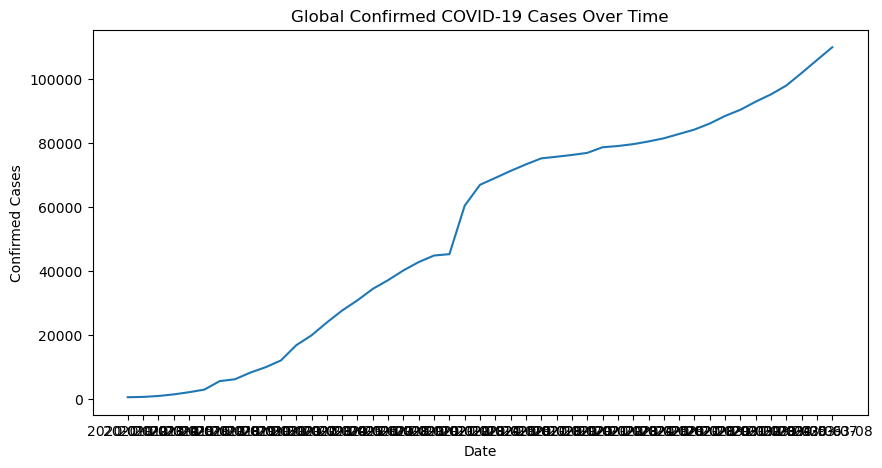

In [23]:
plt.figure(figsize=(10,5))

plt.plot(
    daily_global["observation_date"],
    daily_global["confirmed"]
)

plt.xlabel("Date")
plt.ylabel("Confirmed Cases")
plt.title("Global Confirmed COVID-19 Cases Over Time")

plt.show()

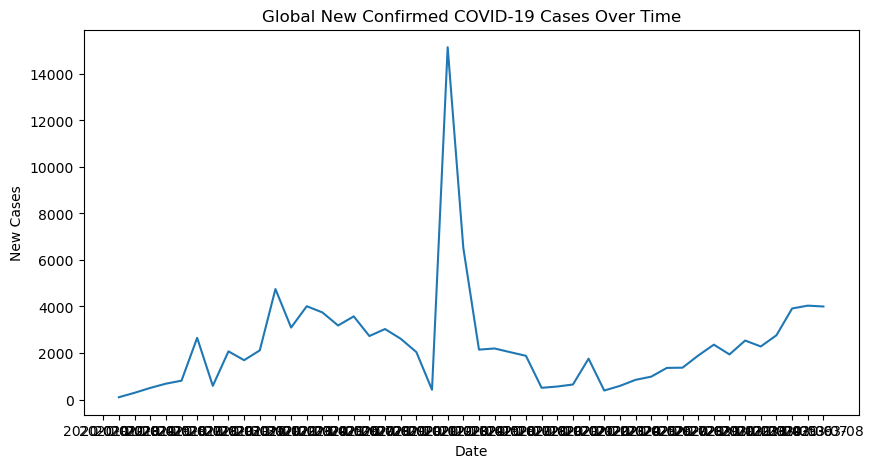

In [24]:
plt.figure(figsize=(10,5))

plt.plot(
    daily_global["observation_date"],
    daily_global["new_cases"]
)

plt.xlabel("Date")
plt.ylabel("New Cases")
plt.title("Global New Confirmed COVID-19 Cases Over Time")

plt.show()

In [25]:
daily_global.sort_values(by='new_cases', ascending=False)

,observation_date,confirmed,deaths,recovered,new_cases,new_deaths,new_recovered
22,2020-02-13,60370,1371,6295,15148.0,253.0,1145.0
23,2020-02-14,66887,1523,8058,6517.0,152.0,1763.0
11,2020-02-02,16787,362,472,4749.0,103.0,188.0
45,2020-03-07,105836,3558,58359,4036.0,98.0,2493.0
13,2020-02-04,23892,492,852,4011.0,66.0,229.0
46,2020-03-08,109835,3803,60695,3999.0,245.0,2336.0
44,2020-03-06,101800,3460,55866,3914.0,112.0,2069.0
14,2020-02-05,27636,564,1124,3744.0,72.0,272.0
16,2020-02-07,34392,719,2011,3574.0,85.0,524.0
15,2020-02-06,30818,634,1487,3182.0,70.0,363.0


In [26]:
daily_global.loc[daily_global["observation_date"] == "2020-02-13"]

,observation_date,confirmed,deaths,recovered,new_cases,new_deaths,new_recovered
22,2020-02-13,60370,1371,6295,15148.0,253.0,1145.0


In [27]:
daily_global.loc[daily_global["new_cases"].idxmax()]

observation_date    2020-02-13
confirmed                60370
deaths                    1371
recovered                 6295
new_cases              15148.0
new_deaths               253.0
new_recovered           1145.0
Name: 22, dtype: object

# improving plots

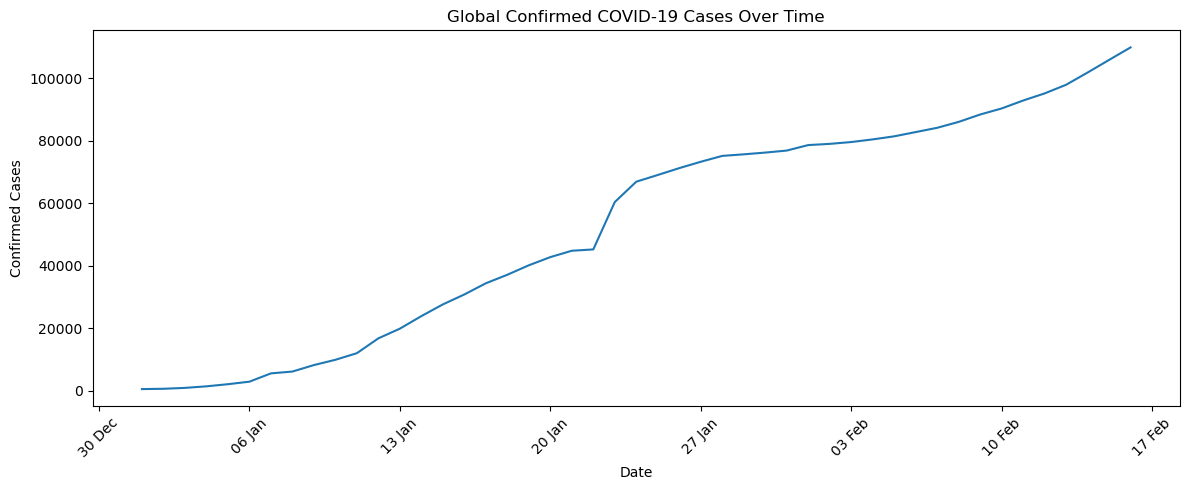

In [28]:
import matplotlib.dates as mdates

plt.figure(figsize=(12, 5))

plt.plot(
    daily_global["observation_date"],
    daily_global["confirmed"]
)

plt.xlabel("Date")
plt.ylabel("Confirmed Cases")
plt.title("Global Confirmed COVID-19 Cases Over Time")

plt.gca().xaxis.set_major_locator(mdates.WeekdayLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

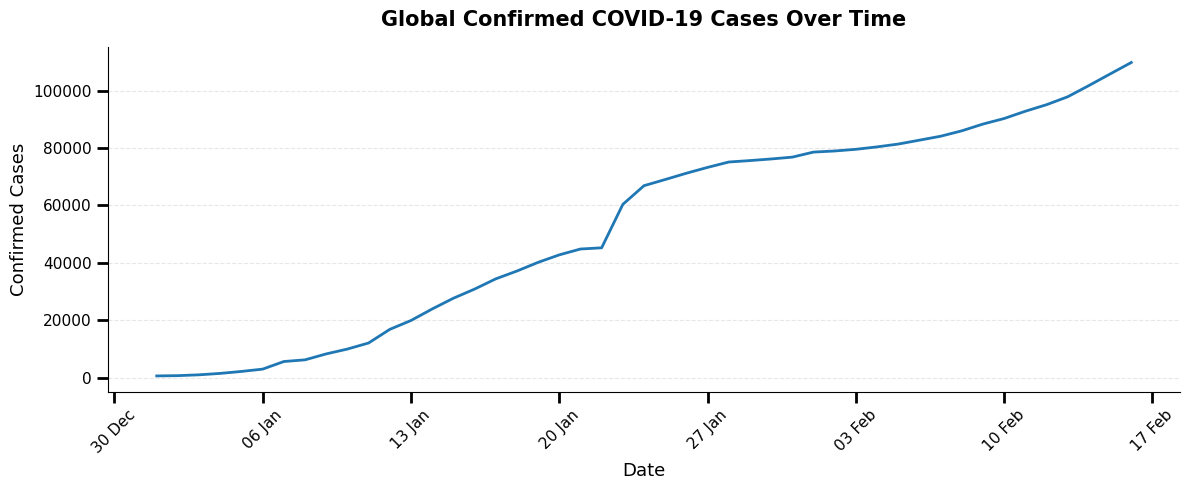

In [79]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    daily_global["observation_date"],
    daily_global["confirmed"],
    linewidth=2
)

ax.set_xlabel("Date", fontsize=13)
ax.set_ylabel("Confirmed Cases", fontsize=13)
ax.set_title(
    "Global Confirmed COVID-19 Cases Over Time",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.xaxis.set_major_locator(mdates.WeekdayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

plt.xticks(rotation=45)

ax.tick_params(
    axis="x",
    labelsize=11,
    length=8,
    width=2,
    rotation=45
)
ax.tick_params(
    axis="y",
    labelsize=11,
    length=8,
    width=2,
    rotation=0
)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

# Save as high-quality PNG
fig.savefig(
    "global_confirmed_cases.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

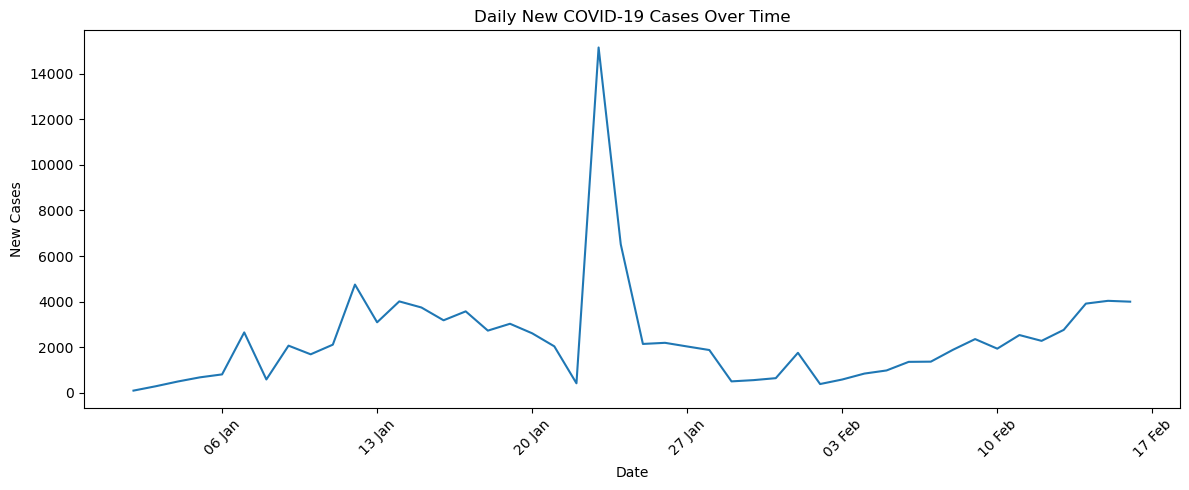

In [29]:
plt.figure(figsize=(12, 5))

plt.plot(
    daily_global["observation_date"],
    daily_global["new_cases"]
)

plt.xlabel("Date")
plt.ylabel("New Cases")
plt.title("Daily New COVID-19 Cases Over Time")

plt.gca().xaxis.set_major_locator(mdates.WeekdayLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

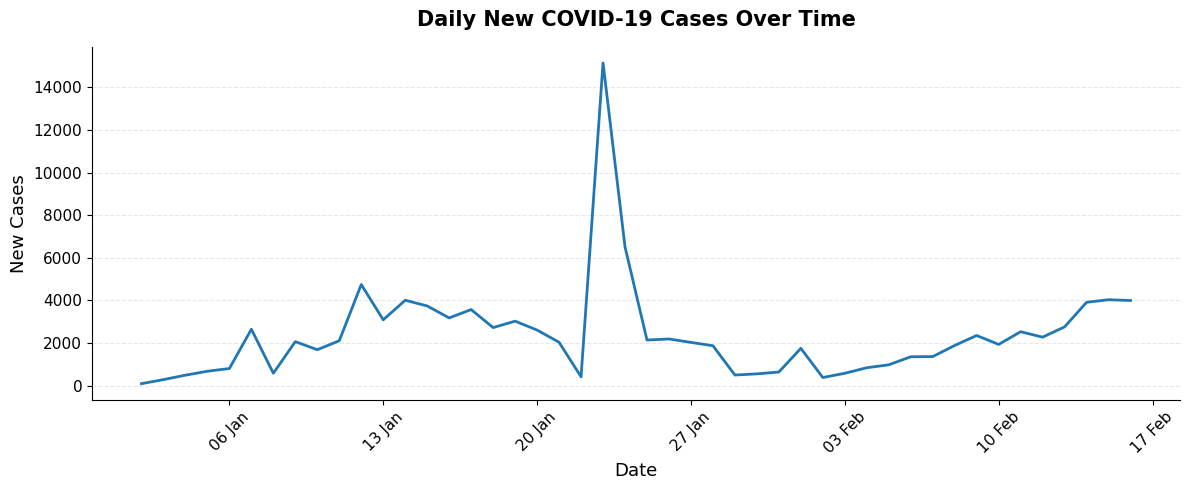

In [80]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    daily_global["observation_date"],
    daily_global["new_cases"],
    linewidth=2
)

ax.set_xlabel("Date", fontsize=13)
ax.set_ylabel("New Cases", fontsize=13)

ax.set_title(
    "Daily New COVID-19 Cases Over Time",
    fontsize=15,
    fontweight="bold",
    pad=15
)

# Format dates
ax.xaxis.set_major_locator(mdates.WeekdayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

plt.xticks(rotation=45)

# Improve readability
ax.tick_params(axis="both", labelsize=11)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Adjust layout
fig.tight_layout()

# Save high-resolution PNG
fig.savefig(
    "daily_global_cases.png",
    dpi=300,
    bbox_inches="tight"
)

# Save vector PDF
fig.savefig(
    "top10_confirmed_cases.png",
    dpi=600,
    bbox_inches="tight"
)
plt.show()

# Which reporting entities had the highest cumulative confirmed cases?

In [30]:
country_cases

,country_region,confirmed
58,Mainland China,67707
47,Italy,7375
96,South Korea,7314
43,Iran,6566
32,France,1126
...,...,...
13,Bhutan,1
107,Ukraine,1
0,Azerbaijan,1
109,Vatican City,1


In [31]:
#sort the ranking
country_cases = country_cases.sort_values("confirmed", ascending=False)

In [32]:
country_cases.head(10)

,country_region,confirmed
58,Mainland China,67707
47,Italy,7375
96,South Korea,7314
43,Iran,6566
32,France,1126
35,Germany,1040
75,Others,706
97,Spain,673
49,Japan,502
100,Switzerland,337


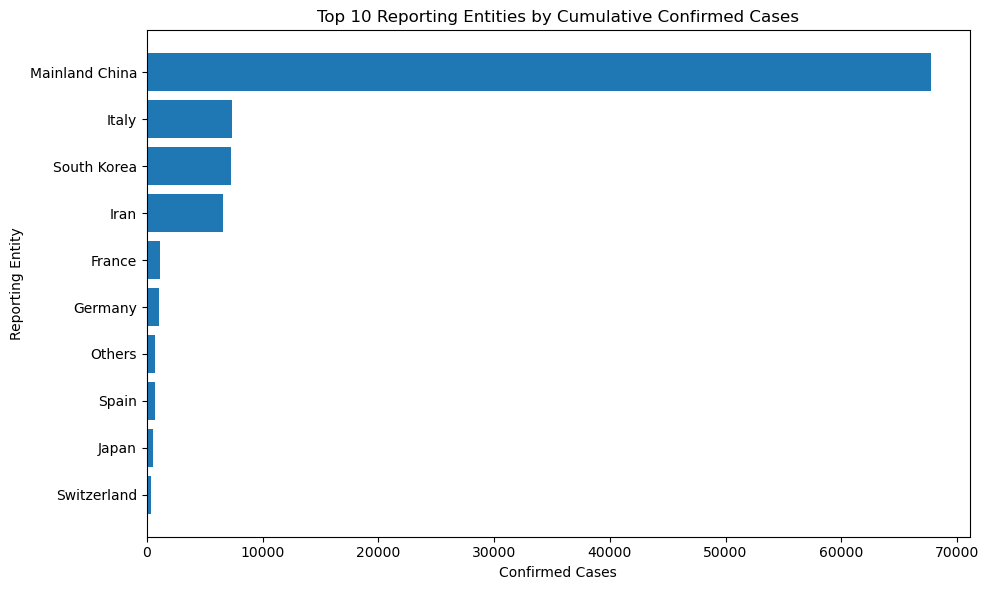

In [33]:
#plot
top10 = country_cases.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top10["country_region"],
    top10["confirmed"]
)

plt.xlabel("Confirmed Cases")
plt.ylabel("Reporting Entity")
plt.title("Top 10 Reporting Entities by Cumulative Confirmed Cases")


plt.gca().invert_yaxis()
plt.tight_layout()

plt.show()

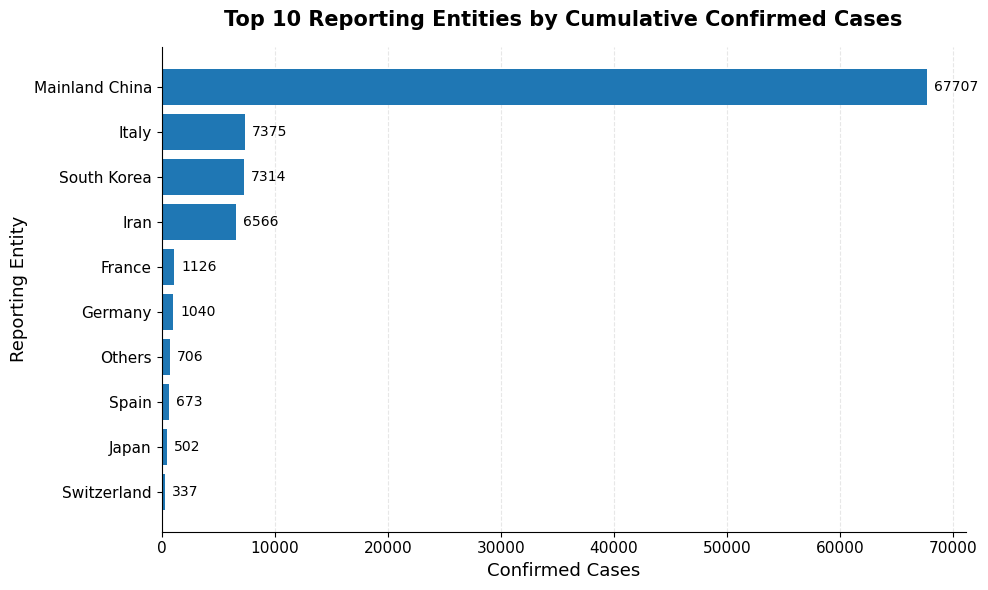

In [81]:
import matplotlib.pyplot as plt

# Top 10 reporting entities
top10 = country_cases.head(10)

# Create figure
fig, ax = plt.subplots(figsize=(10, 6))

# Bar chart
bars = ax.barh(
    top10["country_region"],
    top10["confirmed"],
    linewidth=0
)

# Add values next to bars
ax.bar_label(
    bars,
    fmt="%.0f",
    padding=5,
    fontsize=10
)

# Labels and title
ax.set_xlabel("Confirmed Cases", fontsize=13)
ax.set_ylabel("Reporting Entity", fontsize=13)

# Labels and title
ax.set_xlabel("Confirmed Cases", fontsize=13)
ax.set_ylabel("Reporting Entity", fontsize=13)
ax.set_title(
    "Top 10 Reporting Entities by Cumulative Confirmed Cases",
    fontsize=15,
    fontweight="bold",
    pad=15
)

# Improve tick labels
ax.tick_params(axis="both", labelsize=11)

# Put largest entity at the top
ax.invert_yaxis()

# Add subtle grid
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

# Put grid behind bars
ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Prevent labels from being cut off
fig.tight_layout()

# Save high-resolution PNG
fig.savefig(
    "top10_confirmed_cases.png",
    dpi=300,
    bbox_inches="tight"
)

# Save vector PDF
fig.savefig(
    "top10_confirmed_cases.png",
    dpi=600,
    bbox_inches="tight"
)

# Display in Jupyter
plt.show()

In [57]:
import os
print(os.getcwd())

/home/dell


# Which reporting entities had the highest cumulative deaths?

In [34]:
country_deaths = (DataFileC.groupby("country_region")["deaths"].max().reset_index())

In [35]:
country_deaths = country_deaths.sort_values("deaths", ascending=False)

In [36]:
country_deaths.head(10)

,country_region,deaths
58,Mainland China,2986
47,Italy,366
43,Iran,194
96,South Korea,50
32,France,19
106,US,17
97,Spain,17
44,Iraq,6
75,Others,6
49,Japan,6


In [37]:
#maximum reported cumulative confirmed cases, deaths, and recoveries for each reporting entity.
country_summary = (
    DataFileC.groupby("country_region")
    .agg(
        confirmed = ("confirmed", "max"),
        deaths = ("deaths", "max"),
        recovered = ("recovered", "max")
    )
    .reset_index()    
)

In [38]:
country_summary = country_summary.sort_values("confirmed", ascending=False)

In [39]:
country_summary.head(10)

,country_region,confirmed,deaths,recovered
58,Mainland China,67707,2986,45235
47,Italy,7375,366,622
96,South Korea,7314,50,135
43,Iran,6566,194,2134
32,France,1126,19,12
35,Germany,1040,0,18
75,Others,706,6,40
97,Spain,673,17,30
49,Japan,502,6,76
100,Switzerland,337,2,3


In [40]:
#reported death percentage
country_summary["death_rate"] = np.where(
    country_summary["confirmed"] > 0,
    country_summary['deaths'] / country_summary["confirmed"] * 100,
    0
)

In [41]:
country_summary.sort_values("death_rate", ascending=False).head(10).round({"death_rate": 2})

,country_region,confirmed,deaths,recovered,death_rate
106,US,83,17,2,20.48
80,Philippines,10,1,1,10.00
44,Iraq,60,6,0,10.00
4,Argentina,12,1,0,8.33
6,Australia,38,3,8,7.89
47,Italy,7375,366,622,4.96
58,Mainland China,67707,2986,45235,4.41
43,Iran,6566,194,2134,2.95
88,San Marino,36,1,0,2.78
38,Hong Kong,114,3,58,2.63


# Is there a relationship between the number of confirmed cases and deaths?

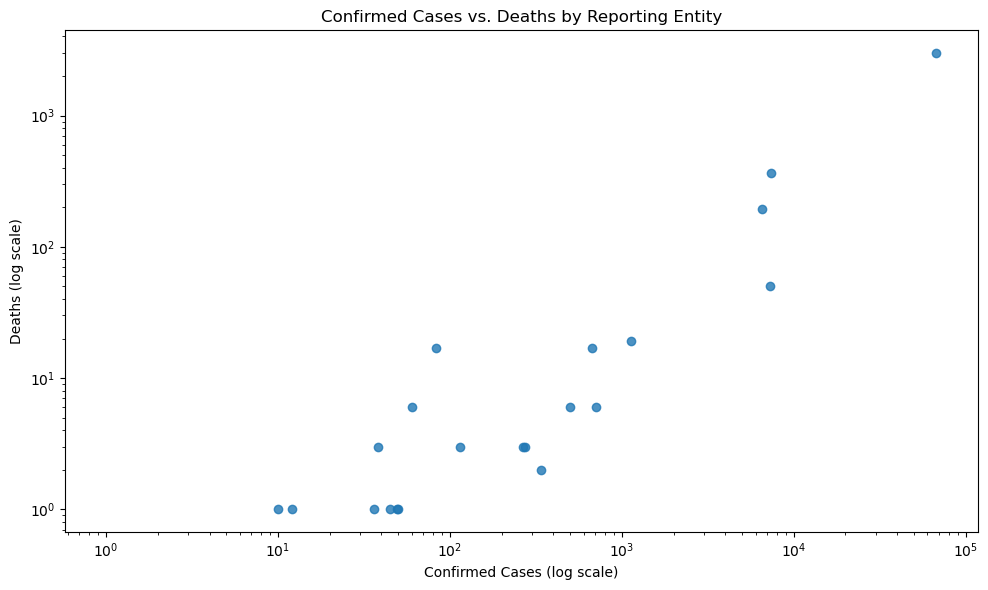

In [42]:
#scater plot:
plt.figure(figsize=(10, 6))

plt.scatter(
    country_summary["confirmed"],
    country_summary["deaths"],
    alpha=0.8
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Confirmed Cases (log scale)")
plt.ylabel("Deaths (log scale)")
plt.title("Confirmed Cases vs. Deaths by Reporting Entity")

plt.tight_layout()
plt.show()

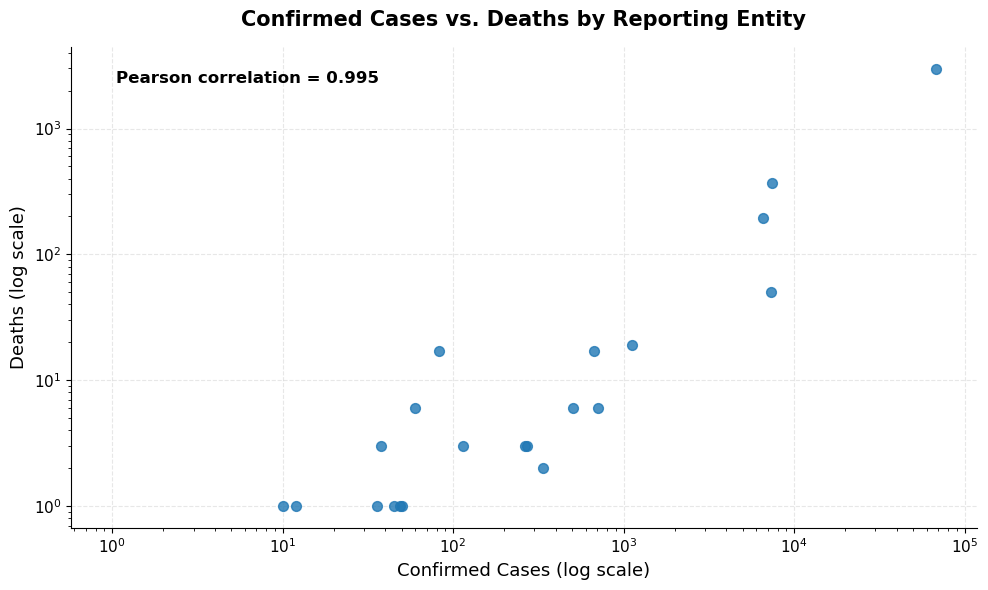

In [82]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    country_summary["confirmed"],
    country_summary["deaths"],
    alpha=0.8,
    s=50
)

# Log scales
ax.set_xscale("log")
ax.set_yscale("log")

# Labels and title
ax.set_xlabel("Confirmed Cases (log scale)", fontsize=13)
ax.set_ylabel("Deaths (log scale)", fontsize=13)

ax.set_title(
    "Confirmed Cases vs. Deaths by Reporting Entity",
    fontsize=15,
    fontweight="bold",
    pad=15
)

# Improve readability
ax.tick_params(axis="both", labelsize=11)

ax.grid(
    True,
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Add Pearson correlation as text
ax.text(
    0.05, 0.95,
    "Pearson correlation = 0.995",
    transform=ax.transAxes,
    fontsize=12,
    fontweight="bold",
    verticalalignment="top"
)

# Adjust layout
fig.tight_layout()

# Save as high-resolution PNG
fig.savefig(
    "confirmed_vs_deaths.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Is there a relationship between confirmed cases and deaths?

In [43]:
country_summary["confirmed"].corr(country_summary["deaths"])

0.9951714030969679

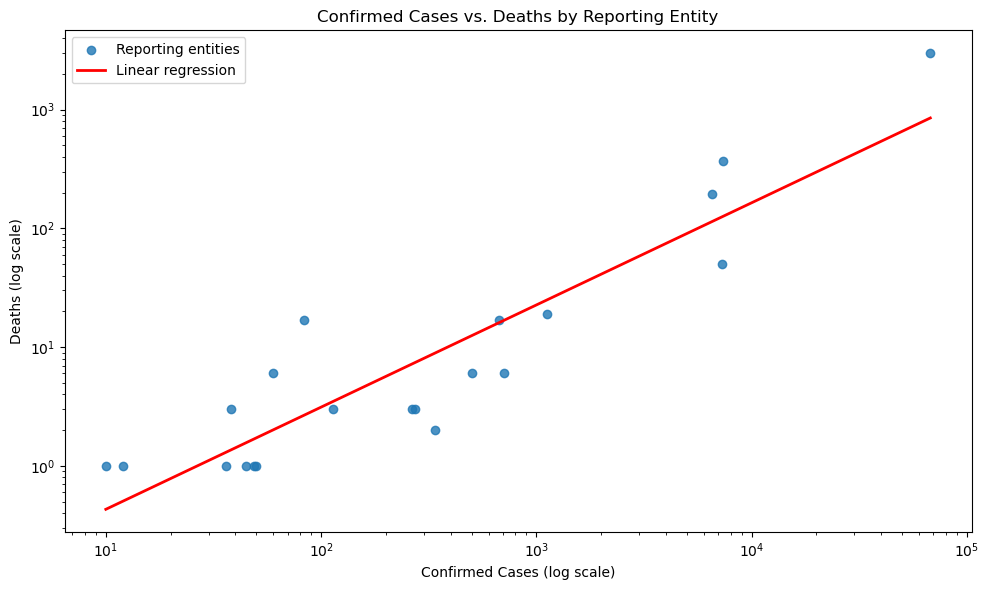

Pearson correlation: 0.9102108645547914


In [44]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Get the data
x = country_summary["confirmed"]
y = country_summary["deaths"]

# Remove zeros because log(0) is undefined
mask = (x > 0) & (y > 0)
x = x[mask]
y = y[mask]

# Log-transform the data
log_x = np.log10(x)
log_y = np.log10(y)

# Calculate linear regression
slope, intercept, r_value, p_value, std_err = linregress(log_x, log_y)

# Calculate predicted values
y_pred = slope * log_x + intercept

# Scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    x,
    y,
    alpha=0.8,
    label="Reporting entities"
)

# Regression line
plt.plot(
    x,
    10**y_pred,
    color="red",
    linewidth=2,
    label="Linear regression"
)



# Log scales
plt.xscale("log")
plt.yscale("log")

plt.xlabel("Confirmed Cases (log scale)")
plt.ylabel("Deaths (log scale)")
plt.title("Confirmed Cases vs. Deaths by Reporting Entity")

plt.legend()
plt.tight_layout()
plt.show()

print("Pearson correlation:", r_value)

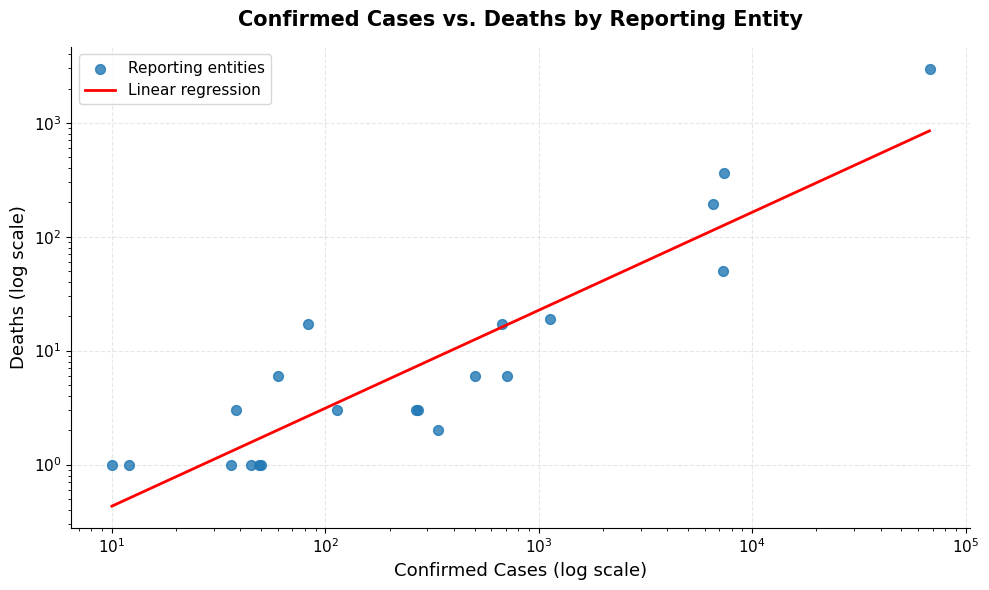

In [62]:
# Create figure
fig, ax = plt.subplots(figsize=(10, 6))

# Scatter plot
ax.scatter(
    x,
    y,
    alpha=0.8,
    s=50,
    label="Reporting entities"
)

# Red regression line
ax.plot(
    x,
    10**y_pred,
    color="red",
    linewidth=2,
    label="Linear regression"
)

# Log scales
ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("Confirmed Cases (log scale)", fontsize=13)
ax.set_ylabel("Deaths (log scale)", fontsize=13)

ax.set_title(
    "Confirmed Cases vs. Deaths by Reporting Entity",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.tick_params(axis="both", labelsize=11)

ax.grid(
    True,
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(fontsize=11)

fig.tight_layout()

# Save as high-quality PNG
fig.savefig(
    "confirmed_vs_deaths_regression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Which reporting entities had the highest number of recovered cases?

In [45]:
country_recovered = DataFileC.groupby("country_region")["recovered"].max().reset_index()    

In [47]:
country_recovered = country_recovered.sort_values("recovered", ascending=False)

In [48]:
country_recovered.head(10)

,country_region,recovered
58,Mainland China,45235
43,Iran,2134
47,Italy,622
96,South Korea,135
92,Singapore,78
49,Japan,76
38,Hong Kong,58
75,Others,40
102,Thailand,31
97,Spain,30


In [49]:
country_summary

,country_region,confirmed,deaths,recovered,death_rate
58,Mainland China,67707,2986,45235,4.410179
47,Italy,7375,366,622,4.962712
96,South Korea,7314,50,135,0.683620
43,Iran,6566,194,2134,2.954615
32,France,1126,19,12,1.687389
...,...,...,...,...,...
13,Bhutan,1,0,0,0.000000
107,Ukraine,1,0,0,0.000000
0,Azerbaijan,1,0,0,0.000000
109,Vatican City,1,0,0,0.000000


In [50]:
country_summary["recovery_rate"] = np.where(
    country_summary["confirmed"] > 0,
    country_summary["recovered"] / country_summary["confirmed"] * 100,
    0
)

In [51]:
country_summary.sort_values("recovery_rate", ascending=False).round({"recovery_rate":2, "death_rate":2}).head(10)

,country_region,confirmed,deaths,recovered,death_rate,recovery_rate
67,Nepal,1,0,1,0.00,100.00
98,Sri Lanka,1,0,1,0.00,100.00
57,Macau,10,0,10,0.00,100.00
58,Mainland China,67707,2986,45235,4.41,66.81
102,Thailand,50,1,31,2.00,62.00
110,Vietnam,30,0,16,0.00,53.33
92,Singapore,150,0,78,0.00,52.00
38,Hong Kong,114,3,58,2.63,50.88
17,Cambodia,2,0,1,0.00,50.00
43,Iran,6566,194,2134,2.95,32.50


# active cases:


In [52]:
country_summary["active"] = (
    country_summary["confirmed"]-
    country_summary["deaths"]-
    country_summary["recovered"]
)

In [53]:
country_summary.sort_values("active", ascending=False).round({"recovery_rate":2, "death_rate":2}).head(10)

,country_region,confirmed,deaths,recovered,death_rate,recovery_rate,active
58,Mainland China,67707,2986,45235,4.41,66.81,19486
96,South Korea,7314,50,135,0.68,1.85,7129
47,Italy,7375,366,622,4.96,8.43,6387
43,Iran,6566,194,2134,2.95,32.50,4238
32,France,1126,19,12,1.69,1.07,1095
35,Germany,1040,0,18,0.00,1.73,1022
75,Others,706,6,40,0.85,5.67,660
97,Spain,673,17,30,2.53,4.46,626
49,Japan,502,6,76,1.20,15.14,420
100,Switzerland,337,2,3,0.59,0.89,332


# peak daily cases

In [54]:
daily_global.loc[
    daily_global["new_cases"].idxmax()
]

observation_date    2020-02-13
confirmed                60370
deaths                    1371
recovered                 6295
new_cases              15148.0
new_deaths               253.0
new_recovered           1145.0
Name: 22, dtype: object

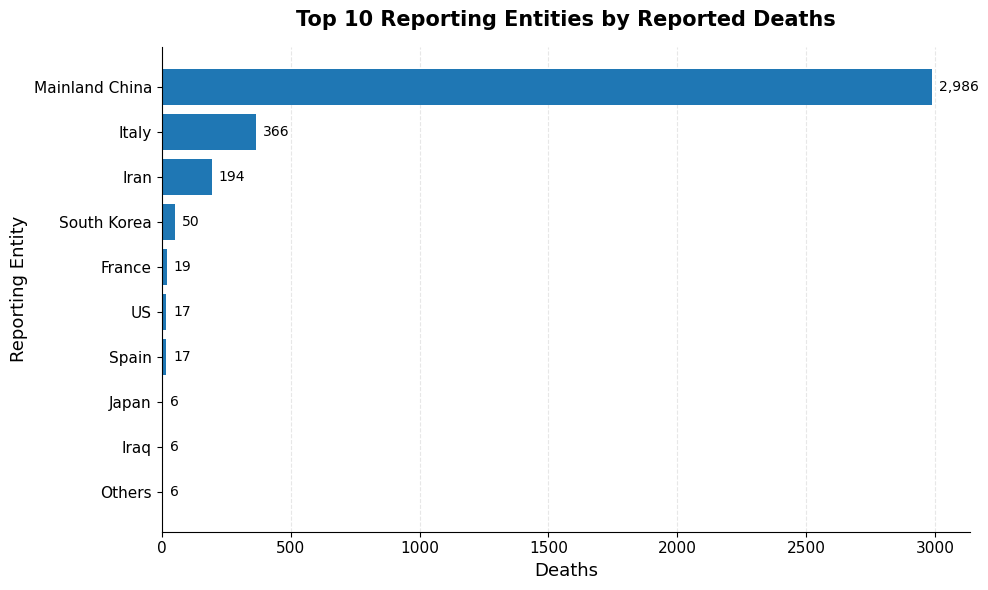

In [83]:
import matplotlib.pyplot as plt

# Top 10 reporting entities by reported deaths
top10_deaths = country_summary.sort_values(
    by="deaths",
    ascending=False
).head(10)

# Create figure
fig, ax = plt.subplots(figsize=(10, 6))

# Horizontal bar chart
bars = ax.barh(
    top10_deaths["country_region"],
    top10_deaths["deaths"],
    linewidth=0
)

# Put largest entity at the top
ax.invert_yaxis()

# Add numerical values next to each bar
ax.bar_label(
    bars,
    fmt=lambda x: f"{x:,.0f}",
    padding=5,
    fontsize=10
)

# Labels and title
ax.set_xlabel("Deaths", fontsize=13)
ax.set_ylabel("Reporting Entity", fontsize=13)

ax.set_title(
    "Top 10 Reporting Entities by Reported Deaths",
    fontsize=15,
    fontweight="bold",
    pad=15
)

# Improve tick labels
ax.tick_params(
    axis="both",
    labelsize=11
)

# Add subtle grid
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

# Put grid behind bars
ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Prevent labels from being cut off
fig.tight_layout()

# Save as high-resolution PNG
fig.savefig(
    "top10_reported_deaths.png",
    dpi=300,
    bbox_inches="tight"
)

# Save vector PDF
fig.savefig(
    "top10_reported_deaths.pdf",
    bbox_inches="tight"
)

# Display in Jupyter
plt.show()